In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = "../datasets/magicbricks/MagicBricks.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1259, 11)


,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Status,Transaction,Type,Per_Sqft
0,800.0,3,2.0,Semi-Furnished,Rohini Sector 25,1.0,6500000,Ready_to_move,New_Property,Builder_Floor,NaN
1,750.0,2,2.0,Semi-Furnished,"J R Designers Floors, Rohini Sector 24",1.0,5000000,Ready_to_move,New_Property,Apartment,6667.0
2,950.0,2,2.0,Furnished,"Citizen Apartment, Rohini Sector 13",1.0,15500000,Ready_to_move,Resale,Apartment,6667.0
3,600.0,2,2.0,Semi-Furnished,Rohini Sector 24,1.0,4200000,Ready_to_move,Resale,Builder_Floor,6667.0
4,650.0,2,2.0,Semi-Furnished,Rohini Sector 24 carpet area 650 sqft status R...,1.0,6200000,Ready_to_move,New_Property,Builder_Floor,6667.0


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
print("\nNumerical Summary:")
display(df.describe())

# Categorical summary
print("\nCategorical Summary:")
display(df.describe(include="object"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Area         1259 non-null   float64
 1   BHK          1259 non-null   int64  
 2   Bathroom     1257 non-null   float64
 3   Furnishing   1254 non-null   object 
 4   Locality     1259 non-null   object 
 5   Parking      1226 non-null   float64
 6   Price        1259 non-null   int64  
 7   Status       1259 non-null   object 
 8   Transaction  1259 non-null   object 
 9   Type         1254 non-null   object 
 10  Per_Sqft     1018 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 108.3+ KB

Missing Values:
Area             0
BHK              0
Bathroom         2
Furnishing       5
Locality         0
Parking         33
Price            0
Status           0
Transaction      0
Type             5
Per_Sqft       241
dtype: int64

Duplicate Rows: 83

Nu

,Area,BHK,Bathroom,Parking,Price,Per_Sqft
count,1259.000000,1259.000000,1257.000000,1226.000000,1.259000e+03,1018.000000
mean,1466.452724,2.796664,2.556086,1.935563,2.130670e+07,15690.136542
std,1568.055040,0.954425,1.042220,6.279212,2.560115e+07,21134.738568
min,28.000000,1.000000,1.000000,1.000000,1.000000e+06,1259.000000
25%,800.000000,2.000000,2.000000,1.000000,5.700000e+06,6364.000000
50%,1200.000000,3.000000,2.000000,1.000000,1.420000e+07,11291.500000
75%,1700.000000,3.000000,3.000000,2.000000,2.550000e+07,18000.000000
max,24300.000000,10.000000,7.000000,114.000000,2.400000e+08,183333.000000



Categorical Summary:


,Furnishing,Locality,Status,Transaction,Type
count,1254,1259,1259,1259,1254
unique,3,365,2,2,2
top,Semi-Furnished,Lajpat Nagar 3,Ready_to_move,Resale,Builder_Floor
freq,708,34,1184,781,661


In [3]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing numerical values with the median
df_clean["Bathroom"] = df_clean["Bathroom"].fillna(
    df_clean["Bathroom"].median()
)

df_clean["Parking"] = df_clean["Parking"].fillna(
    df_clean["Parking"].median()
)

# Fill missing categorical values with the mode
df_clean["Furnishing"] = df_clean["Furnishing"].fillna(
    df_clean["Furnishing"].mode()[0]
)

df_clean["Type"] = df_clean["Type"].fillna(
    df_clean["Type"].mode()[0]
)

# Keep Per_Sqft missing values for now
# We should not invent property prices per square foot.

# Check cleaned dataset
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:", df_clean.duplicated().sum())

Original shape: (1259, 11)
Cleaned shape: (1176, 11)

Missing values after cleaning:
Area             0
BHK              0
Bathroom         0
Furnishing       0
Locality         0
Parking          0
Price            0
Status           0
Transaction      0
Type             0
Per_Sqft       227
dtype: int64

Duplicate rows after cleaning: 0


In [4]:
import os

# Create output folder
os.makedirs("../outputs/magicbricks", exist_ok=True)

# Create cleaned dataset folder
os.makedirs("../datasets/magicbricks", exist_ok=True)

# Save cleaned dataset
df_clean.to_csv(
    "../datasets/magicbricks/MagicBricks_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("File: datasets/magicbricks/MagicBricks_cleaned.csv")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Cleaned dataset saved successfully!
File: datasets/magicbricks/MagicBricks_cleaned.csv
Rows: 1176
Columns: 11


In [5]:
print("Property Price Statistics:")

display(
    df_clean["Price"].describe().to_frame().round(2)
)

print("\nMost expensive properties:")
display(
    df_clean.nlargest(10, "Price")[
        ["Locality", "Area", "BHK", "Bathroom", "Price", "Type"]
    ]
)

print("\nMost affordable properties:")
display(
    df_clean.nsmallest(10, "Price")[
        ["Locality", "Area", "BHK", "Bathroom", "Price", "Type"]
    ]
)

Property Price Statistics:


,Price
count,1.176000e+03
mean,2.109173e+07
std,2.523174e+07
min,1.000000e+06
25%,5.800000e+06
50%,1.400000e+07
75%,2.600000e+07
max,2.400000e+08



Most expensive properties:


,Locality,Area,BHK,Bathroom,Price,Type
57,Lajpat Nagar,8000.0,4,5.0,240000000,Builder_Floor
109,Lajpat Nagar,8000.0,4,5.0,240000000,Builder_Floor
242,"Maharani Bagh, New Friends Colony",6000.0,5,5.0,220000000,Builder_Floor
1210,"Mayfair garden, Hauz Khas",6500.0,4,5.0,190000000,Builder_Floor
1202,"Hauz Khas Apartment, Hauz Khas Enclave, Hauz Khas",6000.0,5,5.0,180000000,Apartment
225,Greater Kailash 2,5025.0,5,6.0,170000000,Builder_Floor
255,"Maharani Bagh, New Friends Colony",8150.0,4,5.0,170000000,Builder_Floor
248,"Maharani Bagh, New Friends Colony",10350.0,4,7.0,160000000,Apartment
585,Safdarjung Enclave,5500.0,6,7.0,160000000,Apartment
253,"Friends Colony East, New Friends Colony",4200.0,5,5.0,135500000,Builder_Floor



Most affordable properties:


,Locality,Area,BHK,Bathroom,Price,Type
893,Narela Sector A5,198.0000,1,1.0,1000000,Apartment
894,"DDA Lig Flats, Narela",4900.0000,1,1.0,1000000,Apartment
895,"DDA Flats Pocket 3, Narela",2077.4327,1,1.0,1000000,Builder_Floor
834,Mehrauli,405.0000,1,1.0,1200000,Builder_Floor
158,Budh Vihar Phase 1,270.0000,2,1.0,1400000,Apartment
886,Narela,350.0000,1,1.0,1490000,Apartment
445,"Baljit Nagar, Patel Nagar",900.0000,2,2.0,1500000,Builder_Floor
756,"Indra Park Palam, Manglapuri",50.0000,1,1.0,1500000,Builder_Floor
778,"Indra Park Palam, Manglapuri",360.0000,1,1.0,1500000,Builder_Floor
810,Mehrauli,405.0000,1,1.0,1500000,Apartment


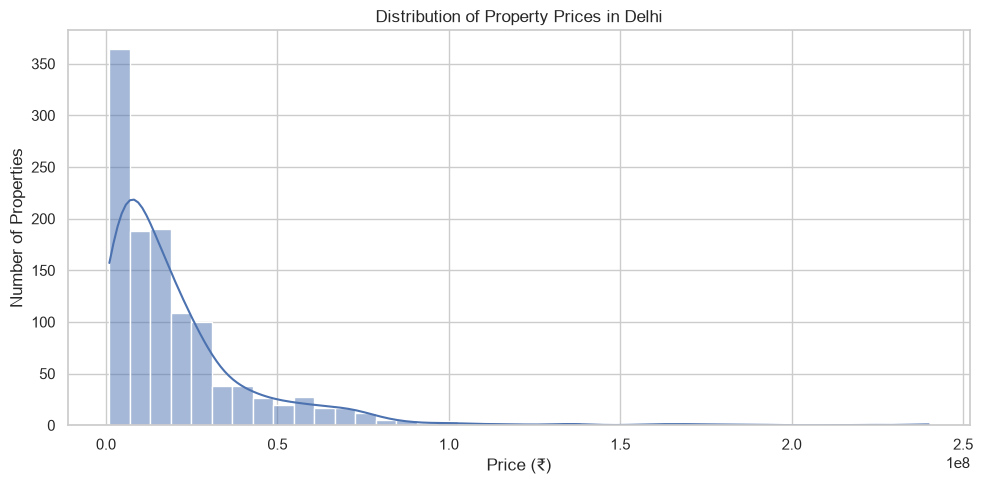

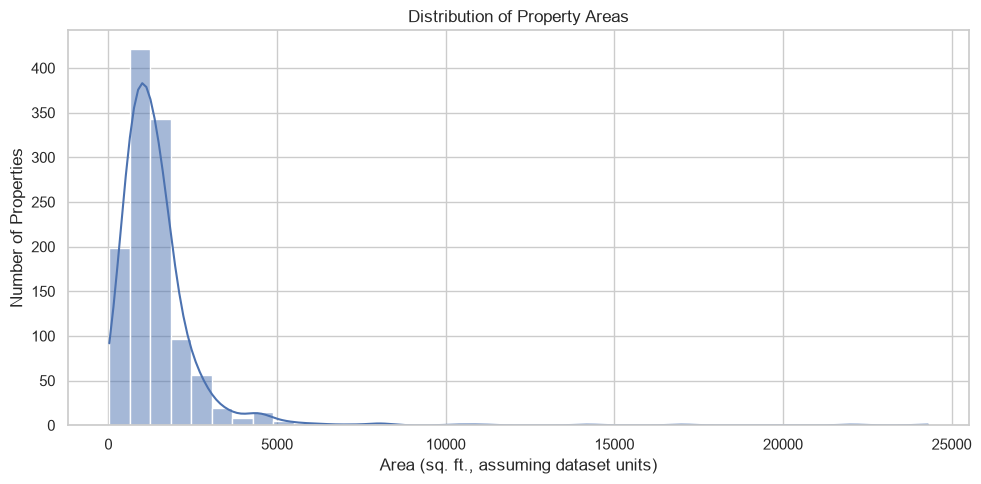

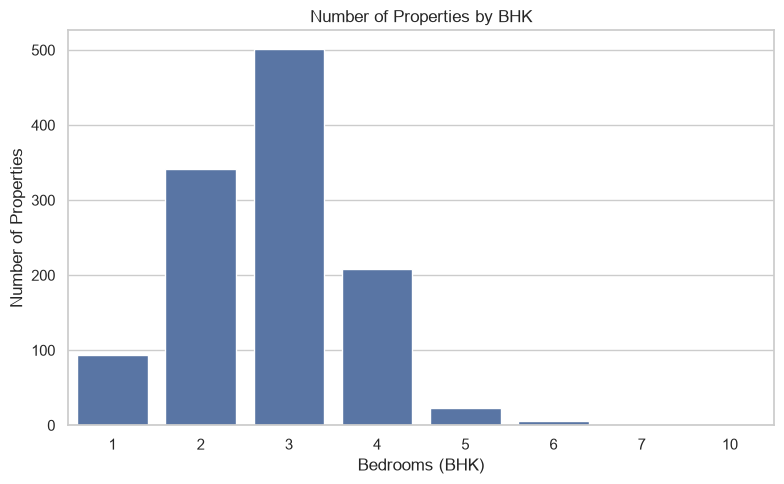

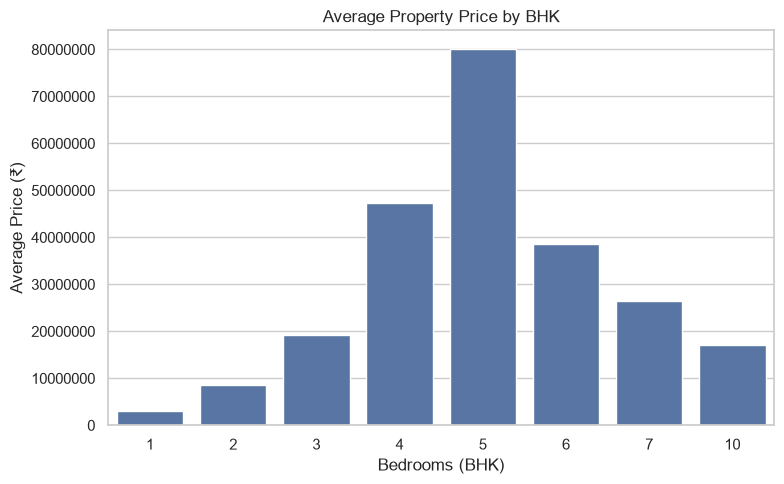

All 4 visualizations saved successfully!
Output folder: ../outputs/magicbricks


In [6]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

output_dir = "../outputs/magicbricks"
os.makedirs(output_dir, exist_ok=True)

sns.set_theme(style="whitegrid")

# 1. Property price distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x="Price", bins=40, kde=True)
plt.title("Distribution of Property Prices in Delhi")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.savefig(f"{output_dir}/01_price_distribution.png", dpi=300)
plt.show()
plt.close()

# 2. Property area distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x="Area", bins=40, kde=True)
plt.title("Distribution of Property Areas")
plt.xlabel("Area (sq. ft., assuming dataset units)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.savefig(f"{output_dir}/02_area_distribution.png", dpi=300)
plt.show()
plt.close()

# 3. Number of properties by BHK
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="BHK")
plt.title("Number of Properties by BHK")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.savefig(f"{output_dir}/03_bhk_distribution.png", dpi=300)
plt.show()
plt.close()

# 4. Average price by BHK
plt.figure(figsize=(8, 5))
sns.barplot(data=df_clean, x="BHK", y="Price", errorbar=None)
plt.title("Average Property Price by BHK")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Average Price (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig(f"{output_dir}/04_average_price_by_bhk.png", dpi=300)
plt.show()
plt.close()

print("All 4 visualizations saved successfully!")
print("Output folder:", output_dir)

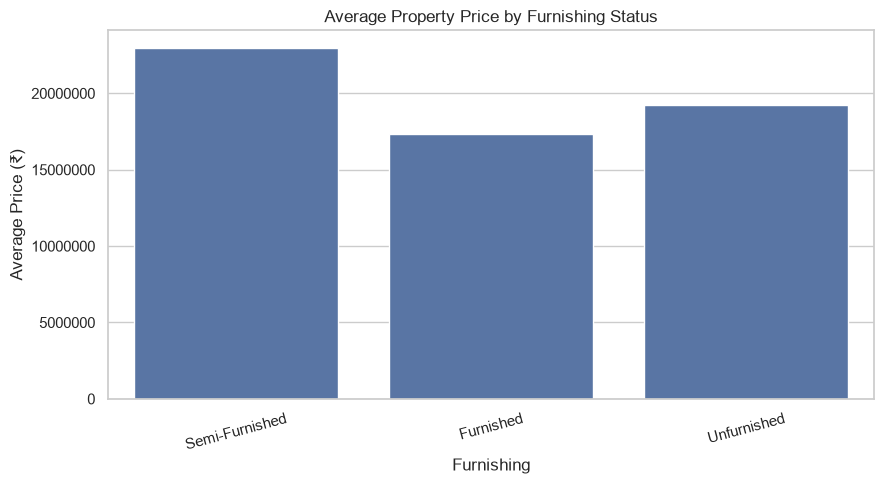

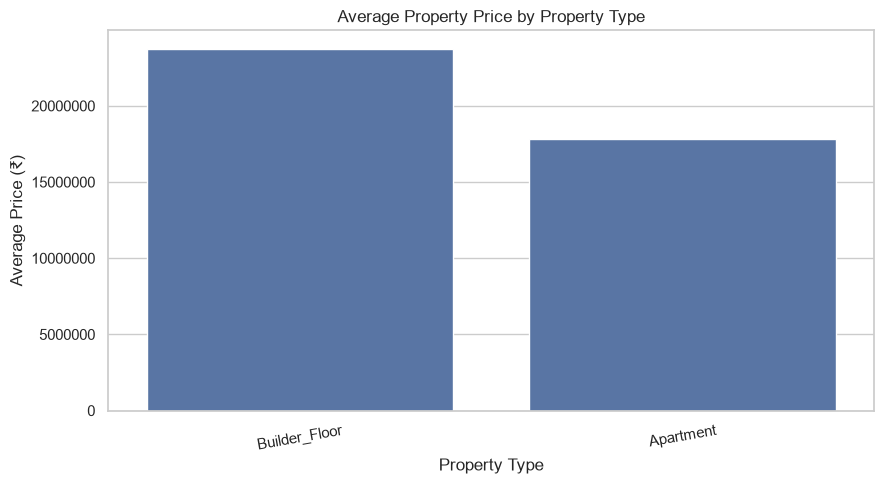

Both visualizations saved successfully!
Files created:
05_average_price_by_furnishing.png
06_average_price_by_type.png


In [7]:
# 5. Average price by furnishing status
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="Furnishing",
    y="Price",
    errorbar=None
)

plt.title("Average Property Price by Furnishing Status")
plt.xlabel("Furnishing")
plt.ylabel("Average Price (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    f"{output_dir}/05_average_price_by_furnishing.png",
    dpi=300
)
plt.show()
plt.close()


# 6. Average price by property type
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="Type",
    y="Price",
    errorbar=None
)

plt.title("Average Property Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(
    f"{output_dir}/06_average_price_by_type.png",
    dpi=300
)
plt.show()
plt.close()

print("Both visualizations saved successfully!")
print("Files created:")
print("05_average_price_by_furnishing.png")
print("06_average_price_by_type.png")

Top 10 Localities by Average Property Price:


,Locality,Average_Price,Property_Count
177,"Maharani Bagh, New Friends Colony",1.214286e+08,7
343,"The Leela Sky Villas, Patel Nagar",8.507500e+07,4
167,Lajpat Nagar,8.164286e+07,7
134,"Hauz Khas Enclave, Hauz Khas",7.681250e+07,8
109,"Friends Colony East, New Friends Colony",7.050000e+07,3
116,"Geetanjali Enclave, Malviya Nagar",6.962500e+07,8
219,New Friends Colony,6.314286e+07,14
132,Hauz Khas,5.608333e+07,12
292,Safdarjung Enclave,5.571111e+07,18
260,Punjabi Bagh West,5.256667e+07,9


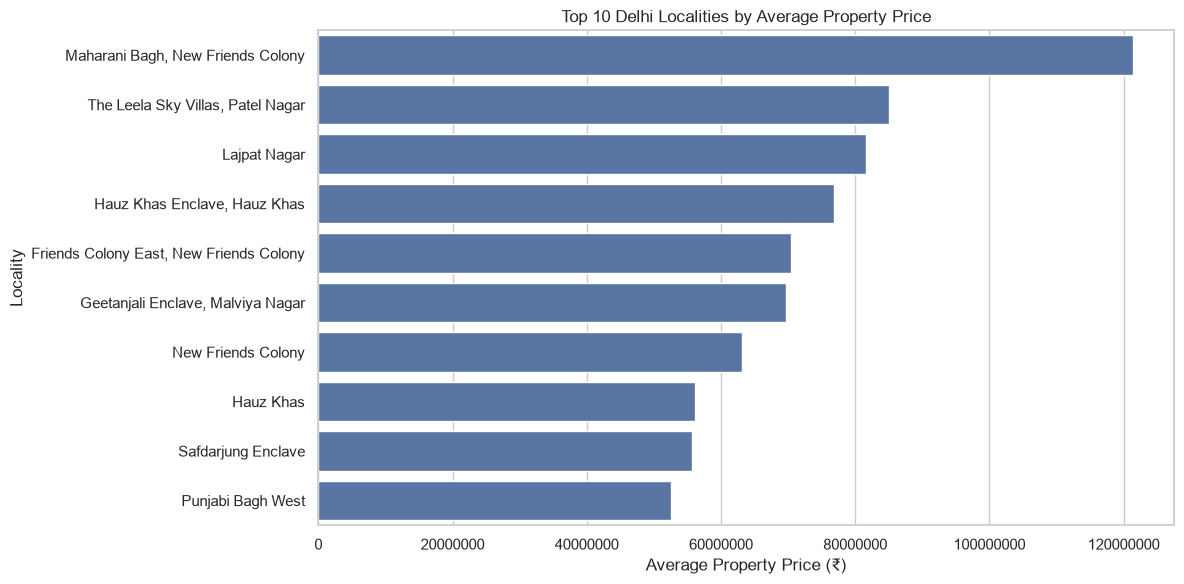

Chart saved: 07_top_localities_by_average_price.png


In [8]:
# Average property price by locality
locality_analysis = (
    df_clean.groupby("Locality")
    .agg(
        Average_Price=("Price", "mean"),
        Property_Count=("Price", "count")
    )
    .reset_index()
)

# Keep localities with at least 3 properties
locality_filtered = locality_analysis[
    locality_analysis["Property_Count"] >= 3
]

# Top 10 localities by average price
top_localities = locality_filtered.nlargest(
    10, "Average_Price"
)

print("Top 10 Localities by Average Property Price:")
display(top_localities.round(2))

# Plot
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_localities,
    x="Average_Price",
    y="Locality",
    errorbar=None
)

plt.title("Top 10 Delhi Localities by Average Property Price")
plt.xlabel("Average Property Price (₹)")
plt.ylabel("Locality")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/07_top_localities_by_average_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Chart saved: 07_top_localities_by_average_price.png")

Correlation Matrix:


,Area,BHK,Bathroom,Parking,Price,Per_Sqft
Area,1.00,0.46,0.55,-0.01,0.60,0.16
BHK,0.46,1.00,0.77,-0.07,0.57,0.18
Bathroom,0.55,0.77,1.00,-0.03,0.73,0.22
Parking,-0.01,-0.07,-0.03,1.00,-0.00,-0.00
Price,0.60,0.57,0.73,-0.00,1.00,0.32
Per_Sqft,0.16,0.18,0.22,-0.00,0.32,1.00


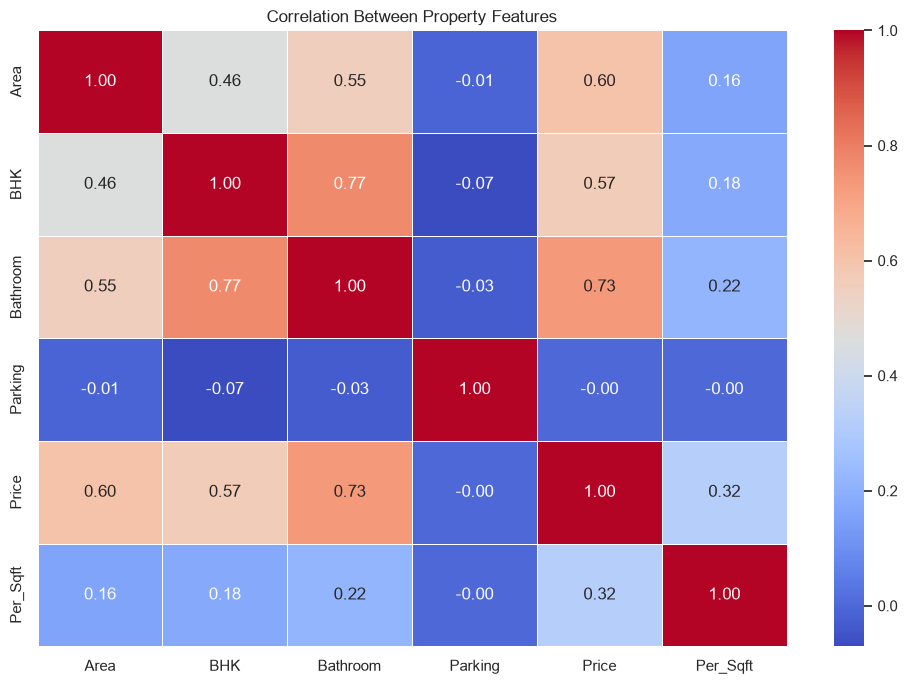

Chart saved: 08_correlation_heatmap.png


In [9]:
# Select numerical columns
numerical_cols = [
    "Area",
    "BHK",
    "Bathroom",
    "Parking",
    "Price",
    "Per_Sqft"
]

# Calculate correlations
correlation_matrix = df_clean[numerical_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Property Features")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/08_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Chart saved: 08_correlation_heatmap.png")

In [10]:
# Missing-value analysis
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Count", ascending=False
)

print("Missing Values Report:")
display(missing_report)

# Save report
missing_report.to_csv(
    f"{output_dir}/09_missing_values_report.csv"
)

print("Report saved: 09_missing_values_report.csv")

Missing Values Report:


,Missing_Count,Missing_Percentage
Per_Sqft,227,19.3
BHK,0,0.0
Area,0,0.0
Bathroom,0,0.0
Furnishing,0,0.0
Parking,0,0.0
Locality,0,0.0
Price,0,0.0
Status,0,0.0
Transaction,0,0.0


Report saved: 09_missing_values_report.csv


In [11]:
# Inspect the 10 largest property areas
print("10 Properties with the Largest Areas:")

display(
    df_clean.nlargest(10, "Area")[
        ["Locality", "Area", "BHK", "Bathroom", "Parking", "Price"]
    ]
)

# Inspect properties with unusually high parking values
print("\nProperties with Parking Greater Than 5:")

display(
    df_clean[df_clean["Parking"] > 5][
        ["Locality", "Area", "BHK", "Bathroom", "Parking", "Price"]
    ].sort_values("Parking", ascending=False)
)

# Check statistical outlier thresholds using the IQR method
q1 = df_clean["Area"].quantile(0.25)
q3 = df_clean["Area"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("\nArea Outlier Analysis:")
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper outlier threshold:", upper_limit)
print("Properties above threshold:", (df_clean["Area"] > upper_limit).sum())

10 Properties with the Largest Areas:


,Locality,Area,BHK,Bathroom,Parking,Price
567,Saket,24300.0,4,5.0,2.0,51000000
234,Greater Kailash 1,22050.0,4,4.0,2.0,51000000
1133,Punjabi Bagh West,17010.0,3,3.0,2.0,25000000
626,Paschim Vihar Block B4,14220.0,3,3.0,1.0,27500000
1258,Chittaranjan Park,11050.0,3,3.0,1.0,18500000
248,"Maharani Bagh, New Friends Colony",10350.0,4,7.0,3.0,160000000
255,"Maharani Bagh, New Friends Colony",8150.0,4,5.0,4.0,170000000
57,Lajpat Nagar,8000.0,4,5.0,1.0,240000000
109,Lajpat Nagar,8000.0,4,5.0,1.0,240000000
268,"Maharani Bagh, New Friends Colony",7200.0,4,4.0,2.0,120000000



Properties with Parking Greater Than 5:


,Locality,Area,BHK,Bathroom,Parking,Price
971,Vasundhara Enclave,950.00,2,2.0,114.0,8100000
969,"Mangal Apartment, Vasundhara Enclave",900.00,2,2.0,114.0,9000000
970,Vasundhara Enclave,1100.00,2,2.0,114.0,10000000
875,Narela,365.00,1,1.0,39.0,3500000
881,"DDA Lig Flats, Narela",350.00,1,1.0,39.0,1600000
877,"DDA Flats Pocket 3, Narela",350.00,1,1.0,39.0,3000000
876,"DDA Lig Flats, Narela",390.00,1,1.0,39.0,2000000
878,"DDA Lig Flats, Narela",210.00,1,1.0,39.0,2000000
879,"DDA Lig Flats, Narela",50.00,1,1.0,39.0,3500000
880,"DDA Pocket H, Narela",500.00,1,1.0,39.0,1800000



Area Outlier Analysis:
Q1: 800.0
Q3: 1700.0
IQR: 900.0
Upper outlier threshold: 3050.0
Properties above threshold: 61


In [12]:
# Count properties by parking value
print("Parking Value Frequencies:")

display(
    df_clean["Parking"]
    .value_counts()
    .sort_index()
    .to_frame(name="Property_Count")
)

# Inspect all properties with suspicious parking values
suspicious_parking = df_clean[df_clean["Parking"] > 5]

print("\nNumber of properties with Parking > 5:",
      len(suspicious_parking))

display(
    suspicious_parking[
        ["Locality", "Area", "BHK", "Bathroom", "Parking", "Price"]
    ].sort_values(["Parking", "Locality"], ascending=[False, True])
)

# Save suspicious records for review
suspicious_parking.to_csv(
    f"{output_dir}/10_suspicious_parking_records.csv",
    index=False
)

print("\nSaved: 10_suspicious_parking_records.csv")

Parking Value Frequencies:


,Property_Count
Parking,
1.0,768
2.0,321
3.0,54
4.0,14
5.0,7
9.0,1
10.0,1
39.0,7
114.0,3



Number of properties with Parking > 5: 12


,Locality,Area,BHK,Bathroom,Parking,Price
969,"Mangal Apartment, Vasundhara Enclave",900.00,2,2.0,114.0,9000000
970,Vasundhara Enclave,1100.00,2,2.0,114.0,10000000
971,Vasundhara Enclave,950.00,2,2.0,114.0,8100000
877,"DDA Flats Pocket 3, Narela",350.00,1,1.0,39.0,3000000
876,"DDA Lig Flats, Narela",390.00,1,1.0,39.0,2000000
878,"DDA Lig Flats, Narela",210.00,1,1.0,39.0,2000000
879,"DDA Lig Flats, Narela",50.00,1,1.0,39.0,3500000
881,"DDA Lig Flats, Narela",350.00,1,1.0,39.0,1600000
880,"DDA Pocket H, Narela",500.00,1,1.0,39.0,1800000
875,Narela,365.00,1,1.0,39.0,3500000



Saved: 10_suspicious_parking_records.csv


In [13]:
# Create a separate dataset for analysis
df_analysis = df_clean.copy()

# Flag suspicious parking values for review
df_analysis["Parking_Flag"] = np.where(
    df_analysis["Parking"] > 5,
    "Review",
    "Normal"
)

print("Parking quality check:")
print(df_analysis["Parking_Flag"].value_counts())

print("\nFlagged records:")
display(
    df_analysis[df_analysis["Parking_Flag"] == "Review"][
        ["Locality", "Area", "BHK", "Parking", "Price", "Parking_Flag"]
    ]
)

# Save analysis dataset
df_analysis.to_csv(
    "../datasets/magicbricks/MagicBricks_analysis.csv",
    index=False
)

print("\nAnalysis dataset saved successfully!")

Parking quality check:
Parking_Flag
Normal    1164
Review      12
Name: count, dtype: int64

Flagged records:


,Locality,Area,BHK,Parking,Price,Parking_Flag
242,"Maharani Bagh, New Friends Colony",6000.00,5,9.0,220000000,Review
875,Narela,365.00,1,39.0,3500000,Review
876,"DDA Lig Flats, Narela",390.00,1,39.0,2000000,Review
877,"DDA Flats Pocket 3, Narela",350.00,1,39.0,3000000,Review
878,"DDA Lig Flats, Narela",210.00,1,39.0,2000000,Review
879,"DDA Lig Flats, Narela",50.00,1,39.0,3500000,Review
880,"DDA Pocket H, Narela",500.00,1,39.0,1800000,Review
881,"DDA Lig Flats, Narela",350.00,1,39.0,1600000,Review
941,"Dilshad Colony, Dilshad Garden",1076.39,3,10.0,9300000,Review
969,"Mangal Apartment, Vasundhara Enclave",900.00,2,114.0,9000000,Review



Analysis dataset saved successfully!


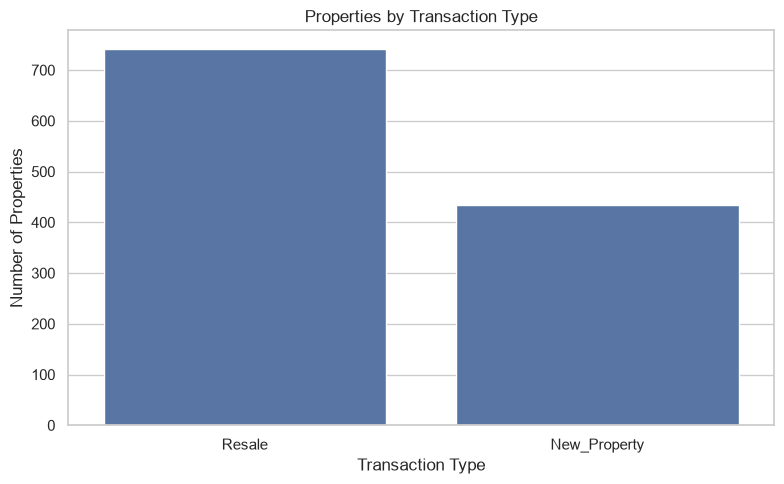

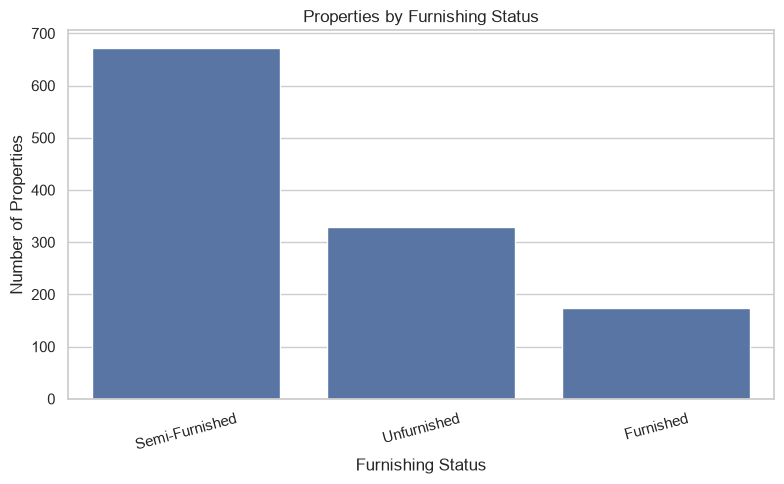

Both visualizations saved successfully!
09_transaction_type_distribution.png
10_furnishing_distribution.png


In [14]:
# 9. Number of properties by transaction type
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Transaction",
    order=df_clean["Transaction"].value_counts().index
)

plt.title("Properties by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Properties")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/09_transaction_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 10. Number of properties by furnishing status
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Furnishing",
    order=df_clean["Furnishing"].value_counts().index
)

plt.title("Properties by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Number of Properties")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/10_furnishing_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Both visualizations saved successfully!")
print("09_transaction_type_distribution.png")
print("10_furnishing_distribution.png")

In [15]:
# Generate final EDA summary report

report_path = f"{output_dir}/MagicBricks_EDA_Summary.txt"

total_properties = len(df_clean)
avg_price = df_clean["Price"].mean()
median_price = df_clean["Price"].median()
min_price = df_clean["Price"].min()
max_price = df_clean["Price"].max()

avg_area = df_clean["Area"].mean()
median_area = df_clean["Area"].median()

avg_bhk = df_clean["BHK"].mean()
avg_bathrooms = df_clean["Bathroom"].mean()

top_locality = top_localities.iloc[0]

parking_review_count = (df_clean["Parking"] > 5).sum()
area_outlier_count = (df_clean["Area"] > upper_limit).sum()

report = f"""
MAGICBRICKS DELHI PROPERTY EDA SUMMARY
======================================

1. DATASET OVERVIEW
-------------------
Original records: {len(df)}
Records after duplicate removal: {total_properties}
Number of columns: {len(df_clean.columns)}
Duplicate records remaining: {df_clean.duplicated().sum()}

2. PROPERTY PRICE ANALYSIS
-------------------------
Average price: Rs. {avg_price:,.2f}
Median price: Rs. {median_price:,.2f}
Minimum price: Rs. {min_price:,.2f}
Maximum price: Rs. {max_price:,.2f}

3. PROPERTY CHARACTERISTICS
---------------------------
Average area value: {avg_area:,.2f}
Median area value: {median_area:,.2f}
Average BHK: {avg_bhk:.2f}
Average bathrooms: {avg_bathrooms:.2f}

4. DATA QUALITY
---------------
Missing Per_Sqft values: {df_clean["Per_Sqft"].isnull().sum()}
Missing Per_Sqft percentage:
{df_clean["Per_Sqft"].isnull().mean() * 100:.2f}%

Properties with area above IQR threshold: {area_outlier_count}
Properties with parking above 5: {parking_review_count}

5. LOCALITY ANALYSIS
--------------------
Highest average-price locality among localities
with at least 3 properties: {top_locality["Locality"]}
Average listed price: Rs. {top_locality["Average_Price"]:,.2f}
Number of properties: {int(top_locality["Property_Count"])}

6. IMPORTANT NOTES
------------------
- Exact duplicate rows were removed.
- Missing numerical and categorical values were handled.
- Missing Per_Sqft values were retained, not imputed.
- Large area values were flagged for investigation, not deleted.
- Parking values above 5 were flagged for review.
- Correlation indicates association, not causation.
- Prices are dataset listing values, not verified valuations.

======================================
End of Report
"""

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print(report)
print("\nSummary report saved successfully!")
print(report_path)


MAGICBRICKS DELHI PROPERTY EDA SUMMARY

1. DATASET OVERVIEW
-------------------
Original records: 1259
Records after duplicate removal: 1176
Number of columns: 11
Duplicate records remaining: 0

2. PROPERTY PRICE ANALYSIS
-------------------------
Average price: Rs. 21,091,726.19
Median price: Rs. 14,000,000.00
Minimum price: Rs. 1,000,000.00
Maximum price: Rs. 240,000,000.00

3. PROPERTY CHARACTERISTICS
---------------------------
Average area value: 1,447.54
Median area value: 1,172.50
Average BHK: 2.79
Average bathrooms: 2.55

4. DATA QUALITY
---------------
Missing Per_Sqft values: 227
Missing Per_Sqft percentage:
19.30%

Properties with area above IQR threshold: 61
Properties with parking above 5: 12

5. LOCALITY ANALYSIS
--------------------
Highest average-price locality among localities
with at least 3 properties: Maharani Bagh, New Friends Colony
Average listed price: Rs. 121,428,571.43
Number of properties: 7

6. IMPORTANT NOTES
------------------
- Exact duplicate rows were

In [16]:
import os

print("MAGICBRICKS EDA OUTPUT FILES")
print("=" * 40)

for folder in ["../outputs/magicbricks", "../datasets/magicbricks"]:
    print(f"\nFolder: {folder}")

    files = sorted(os.listdir(folder))

    for filename in files:
        full_path = os.path.join(folder, filename)

        if os.path.isfile(full_path):
            size_kb = os.path.getsize(full_path) / 1024
            print(f"{filename} ({size_kb:.2f} KB)")

    print("Total files:", len(files))

MAGICBRICKS EDA OUTPUT FILES

Folder: ../outputs/magicbricks
01_price_distribution.png (109.28 KB)
02_area_distribution.png (123.32 KB)
03_bhk_distribution.png (70.17 KB)
04_average_price_by_bhk.png (80.04 KB)
05_average_price_by_furnishing.png (91.95 KB)
06_average_price_by_type.png (82.73 KB)
07_top_localities_by_average_price.png (176.34 KB)
08_correlation_heatmap.png (181.77 KB)
09_missing_values_report.csv (0.20 KB)
09_transaction_type_distribution.png (79.65 KB)
10_furnishing_distribution.png (94.46 KB)
10_suspicious_parking_records.csv (1.29 KB)
11_missing_values_report.csv (0.20 KB)
12_suspicious_parking_records.csv (1.29 KB)
MagicBricks_EDA_Summary.txt (1.46 KB)
Total files: 15

Folder: ../datasets/magicbricks
MagicBricks.csv (153.88 KB)
MagicBricks_analysis.csv (161.92 KB)
MagicBricks_cleaned.csv (153.87 KB)
Total files: 3
